# 由 IR 预测 HOMO–LUMO 能隙

根据谱图估计分子的 HOMO–LUMO 能隙。

岭回归模型使用合并频段后的振动谱强度及与参考谱的相似度。软件根据输入通道选择模型，输出单位为 eV。

本教程读取保存的预测，解释输入输出字段，并评估结果。最后给出在新数据集上运行模型的命令。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('vibrational.gap.ir')
print('Task:', evidence['task'])
print('Examples:', len(evidence['examples']))

Task: vibrational.gap.ir
Examples: 3


## 输入与输出

| Field | Meaning |
| --- | --- |
| `IR / Raman` | 每个可见通道 1024 个强度点，按 400→4000 cm⁻¹ 排列，并采用 checkpoint 的归一化。 |
| `model selection` | 根据提供的振动谱通道选择相应的能隙回归模型。 |

| Field | Meaning |
| --- | --- |
| `gap_ev` | 一个 HOMO–LUMO gap 预测值（eV）；原始 Hartree 标签仅转换一次。 |
| `MAE / baseline` | 与参考值的误差，以及相同样本上固定训练均值基线的误差。 |

查看下面的示例记录。长数组显示长度与前几个数值，下载 JSON 可获取完整数组。

In [2]:
for example in evidence['examples'][:3]:
    print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "sample_id": "ZINCV2-ZINC000666646493",
  "output": {
    "gap_ev": 5.634759166292478
  },
  "reference": {
    "gap_ev": 5.227035183991835
  },
  "input": {
    "ir": {
      "length": 1024,
      "first_values": [
        0.010713187977671623,
        0.013313207775354385,
        0.017257077619433403,
        0.021930798888206482,
        0.02480231784284115,
        0.023212244734168053,
        0.018831992521882057,
        0.014817541465163231
      ]
    }
  }
}
{
  "sample_id": "ZINCV2-ZINC000309053125",
  "output": {
    "gap_ev": 5.581279511977474
  },
  "reference": {
    "gap_ev": 4.712195756217741
  },
  "input": {
    "ir": {
      "length": 1024,
      "first_values": [
        0.022391103208065033,
        0.02813413180410862,
        0.03219398483633995,
        0.030492456629872322,
        0.024626489728689194,
        0.018868830054998398,
        0.01477830857038498,
        0.012172157876193523
      ]
    }
  }
}
{
  "sample_id": "SDBS-34939",
  "output": {
 

## 评估预测

报告以 eV 为单位的 MAE 与 RMSE。

表格给出每次运行的数据集与指标。后续代码从绘图使用的预测值重新计算汇总结果。

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded sample | recorded model | mae_ev | 1.17771 |
| recorded sample | recorded model | rmse_ev | 1.47487 |
| recorded sample | recorded model | examples | 128 |
| recorded sample | Training-mean baseline | constant_ev | 5.64512 |
| recorded sample | Training-mean baseline | mae_ev | 0.89994 |
| recorded sample | Training-mean baseline | rmse_ev | 1.06962 |
| recorded sample | Training-mean baseline | examples | 128 |


{
  "paired_values": 128,
  "mae": 1.1777104695762848,
  "rmse": 1.4748687542942966,
  "unit": "eV"
}


## 查看结果图

预测值与参考值。

比较预测与参考，查看返回的结构或峰位置。图由上方读取的记录直接生成。

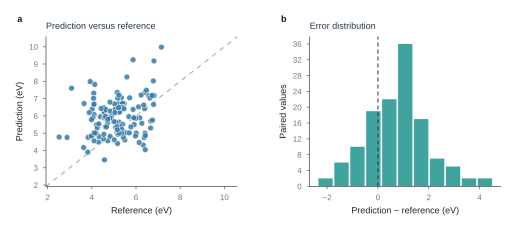

In [4]:
import matplotlib.pyplot as plt
for example_index in range(1):
    figure = render('vibrational.gap.ir', evidence, example_index=example_index)
    image = io.StringIO()
    figure.savefig(image, format='svg', metadata={'Date': None})
    display(SVG(image.getvalue()))
    plt.close(figure)

## 运行模型

按任务指南配置环境和权重，在 benchmark runner 中选择本任务，即可评估自己的数据集。

```bash
python -m openmolspec_bench run --workspace /path/to/OpenMolSpec \
  --tasks vibrational.gap.ir --limit 8 --output results/vibrational-gap-ir.json
```

[Task](../tasks/vibrational-gap-ir.md) · [Quick start](../quickstart.md)



## 参考文献

- OpenMolSpec contributors. openSpec models and benchmark training workflows. Source archive, v1.0 (2026). [Source](https://github.com/jiaqingxie/openmolspec-studio-frontend/tree/release/openmolspec-v1/documentation/assets/benchmarks)
- OpenMolSpec contributors. OpenMolSpec: Chemical spectroscopy datasets, models and learning workflows. Software release v1.0 (2026). [Source](https://github.com/jiaqingxie/openmolspec-studio-frontend/releases/tag/v1.0)
- Yuan, M., Zou, Z. & Hu, W. QMe14S, A Comprehensive and Efficient Spectral Dataset for Small Organic Molecules. arXiv:2501.18876 (2025). [Source](https://arxiv.org/abs/2501.18876)
- Zou, Z., Zhang, Y., Liang, L., Wei, M., Leng, J., Jiang, J., Luo, Y. & Hu, W. A deep learning model for predicting selected organic molecular spectra. Nature Computational Science 3, 957–964 (2023). doi:10.1038/s43588-023-00550-y. [Source](https://www.nature.com/articles/s43588-023-00550-y)
